In [1]:
from utils import *
import matplotlib as mpl
import matplotlib.ticker as ticker

inches_per_pt = 1 / 72.27
gr = (np.sqrt(5) - 1) / 2
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    "font.family": "cmr",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "text.latex.preamble": r"\usepackage[OT1]{fontenc}\usepackage{physics}"
}

plt.rcParams.update(tex_fonts)

In [2]:
fp = FidelityPlotter("zz_II", "II", vmin=0.9)
dm = fp.get_coarse_mats()
fp._get_best_gate_text_coarse()
Latex(fp.get_best_gate_text_polar())


<IPython.core.display.Latex object>

In [3]:
mats = {}
for i, params in enumerate(["beta", "zz"]):
    for j, config in enumerate(["II", "III"]):
        if params == "zz":
            fp = FidelityPlotter(params + "_" + config, config)
        else:
            fp = FidelityPlotter(params, config)
        coarse_mats = fp.get_coarse_mats()
        mats[f"{params}_{config}_coarse"] = coarse_mats

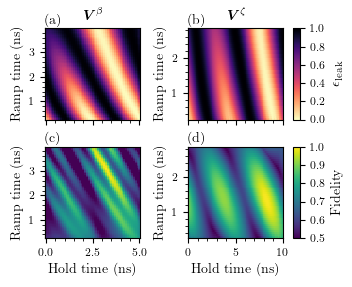

In [4]:
fig, ax = plt.subplots(
    2,
    2,
    figsize=(246 * inches_per_pt, 246 * 0.8 * inches_per_pt),
    sharex="col",
)

# y_unit = "sigma"
y_unit = "ns"

config = "III"

vmin = 0.5
all_pcols = []
for i, params in enumerate(["beta", "zz"]):
    coarse_mats = mats[f"{params}_{config}_coarse"]

    if config == "II":
        z = (
            np.abs(0.5 - np.abs(coarse_mats.overlaps[:, :, 1, 2]) ** 2)
            + np.abs(0.5 - np.abs(coarse_mats.overlaps[:, :, 1, 1]) ** 2)
            + np.abs(0.5 - np.abs(coarse_mats.overlaps[:, :, 2, 1]) ** 2)
            + np.abs(0.5 - np.abs(coarse_mats.overlaps[:, :, 2, 2]) ** 2)
        ) / 2

    elif config == "III":
        z = np.abs(1.0 - np.abs(coarse_mats.overlaps[:, :, 3, 3]) ** 2)

    pcol = ax[0, i].pcolormesh(
        coarse_mats.hold_times,
        coarse_mats.sigmas,
        z,
        vmin=0,
        vmax=1.0,
        linewidth=0.0001,
        edgecolors="face",
        cmap="magma_r",
    )

    all_pcols.append(pcol)

    pcol = ax[1, i].pcolormesh(
        coarse_mats.hold_times,
        coarse_mats.sigmas,
        coarse_mats.opt_fid,
        vmin=vmin,
        vmax=1.0,
        linewidth=0.0001,
        edgecolors="face",
    )
    all_pcols.append(pcol)

    


label = ["(a)", "(b)", "(c)", "(d)"]
titles = [
    r"$\vb*{V}^\beta$",
    r"$\vb*{V}^\zeta$",
    r"$\mathbf{V}^\beta$",
    r"$\mathbf{V}^\zeta$",
]
for i, a in enumerate(ax.flatten()):
    if y_unit == "ns":
        secax = a.secondary_yaxis(
            "left",
            functions=(lambda y: 4 * np.sqrt(2) * y, lambda y: y / (4 * np.sqrt(2))),
        )
        secax.set_ylabel("Ramp time (ns)")
        secax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
        a.yaxis.set_visible(False)
    else:
        a.set_ylabel(r"$\sigma$")
        a.yaxis.set_minor_locator(ticker.AutoMinorLocator())

    a.text(0, 1.01, label[i], transform=a.transAxes, ha="left", va="bottom")
    a.xaxis.set_minor_locator(ticker.AutoMinorLocator())

for i, a in enumerate(ax[0, :]):
    a.set_title(titles[i])

for a in ax[1, :]:
    a.set_xlabel("Hold time (ns)")

ax[1, 0].set_xticks([0, 2.5, 5])
if config == "II":
    ax[1, 1].set_xticks([0, 2.5, 5])
if config == "III":
    ax[1, 1].set_xticks([0, 5, 10])

plt.subplots_adjust(
    left=0.12, top=0.92, bottom=0.15, right=0.82, wspace=0.5, hspace=0.3
)

labels = [
    r"$\epsilon_\mathrm{swap}$" if config == "II" else r"$\epsilon_\mathrm{leak}$",
    "Fidelity",
]
for i, a in enumerate(ax[:, 1]):
    cbar_ax = fig.add_axes(
        [
            ax[i, 1].get_position().x1 + 0.03,
            ax[i, 1].get_position().y0,
            0.02,
            ax[i, 1].get_position().y1 - ax[i, 1].get_position().y0,
        ]
    )

    cbar = fig.colorbar(
        all_pcols[i],
        cax=cbar_ax,
        ax=ax[0, :].flatten(),
        ticks=np.linspace(0.5 * i, 1.0, 6),
    )
    cbar.set_label(labels[i])

plt.savefig(f"figs/overlap+fidelity_{'iswap' if config == 'II' else 'cz'}.pdf", dpi=600)

plt.show()

## Gate details

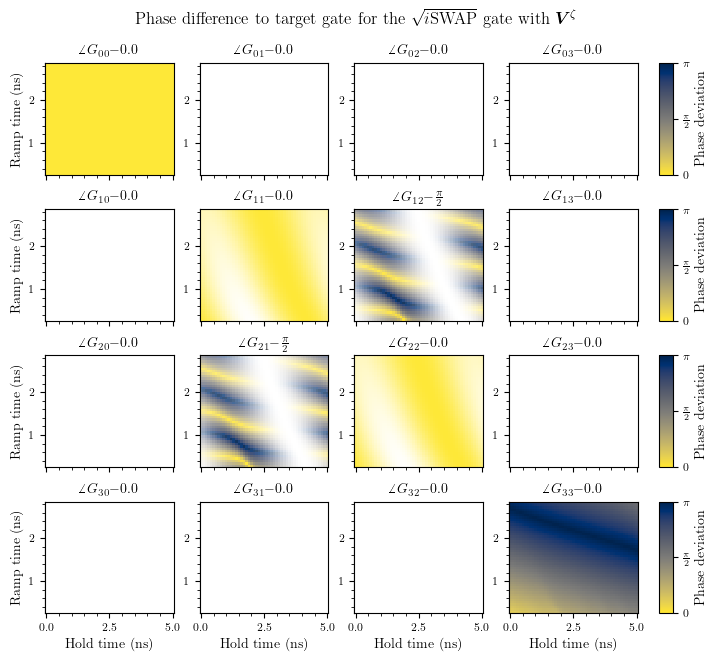

In [5]:
fig, ax = plt.subplots(
    4,
    4,
    figsize=(510 * inches_per_pt, 510 * 0.95 * inches_per_pt),
    sharex=True,
    sharey=True,
)

config = "II"
params = "beta"

# Optimal hold and ramp times for each gate
opt_times = {"beta_II": [0.6, 0.09], "zz_II": [0.1, 0.25], "beta_III": [3.2, 0.55], "zz_III": [8.3, 0.24]}

all_pcols = []

coarse_mats = mats[f"{params}_{config}_coarse"]
res = coarse_mats.gate_mats

for i in range(4):
    ax[3, i].set_xlabel("Hold time (ns)")

    for j in range(4):
        ang_diff = np.abs(
            np.mod(
                np.angle(res[:, :, i, j]) - np.angle(U_0[config][i, j]) + np.pi,
                2 * np.pi,
            )
            - np.pi
        )
        ang_max = np.pi

        abs_diff = np.abs(np.abs(res[:, :, i, j]) ** 2)
        abs_max = 1

        # Normalize ang_diff for colormap
        ang_norm = ang_diff / max(np.max(ang_diff), ang_max)
        # Normalize abs_diff for alpha
        alpha = abs_diff / max(np.max(abs_diff), abs_max)

        # Get RGBA from colormap, set alpha to abs_diff
        rgba = plt.cm.cividis_r(ang_norm)
        rgba = contract("ijk, ij -> ijk", rgba, alpha) + contract(
            "ij,k -> ijk", (1 - alpha), np.array([1, 1, 1, 1])
        )  # blend with white

        def get_label(value):
            label_dict = {
                0.00: "0.0",
                1.00: "1.0",
                1.57: r"$\frac{\pi}{2}$",
                3.14: r"$\pi$",
            }
            sign = "" if value >= 0 else "-"
            return sign + label_dict.get(
                np.abs(np.round(value, 2)), str(np.abs(np.round(value, 2)))
            )

        pcol_1 = ax[i, j].pcolormesh(
            coarse_mats.hold_times,
            coarse_mats.sigmas,
            rgba,
            vmin=0,
            vmax=ang_max,
            linewidth=0.0001,
            edgecolors="face",
            cmap="cividis_r",
        )
        ax[i, j].set_title(
            r"$\angle G_{"
            + str(i)
            + str(j)
            + r"} - $"
            + get_label(np.angle(U_0[config][i, j])),
            fontsize=10,
        )

        # Mark optimal point?
        #ax[i,j].plot(*opt_times[f"{params}_{config}"], 'rx')

        all_pcols.append(pcol_1)


fig.subplots_adjust(left=0.06, top=0.9, bottom=0.08, right=0.9, wspace=0.2, hspace=0.31)

for i, _ in enumerate(ax[:, 3]):
    cbar_ax = fig.add_axes(
        [
            ax[i, 3].get_position().x1 + 0.03,
            ax[i, 3].get_position().y0,
            0.02,
            ax[i, 3].get_position().y1 - ax[i, 3].get_position().y0,
        ]
    )

    cbar = fig.colorbar(
        all_pcols[i],
        cax=cbar_ax,
        ax=ax[0, :].flatten(),
        ticks=[0, np.pi / 2, np.pi],
        format=ticker.FixedFormatter(
            [r"$0$", r"$\frac{\pi}{2}$", r"$\pi$"],
        ),
        label="Phase deviation",
    )

for i, a in enumerate(ax.flatten()):
    secax = a.secondary_yaxis(
        "left",
        functions=(lambda y: 4 * np.sqrt(2) * y, lambda y: y / (4 * np.sqrt(2))),
    )
    secax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    if i in [0, 4, 8, 12]:
        secax.set_ylabel("Ramp time (ns)")
    a.yaxis.set_visible(False)
    a.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    if params == "zz" and config == "III":
        a.set_xticks([0, 5, 10])
    else:
        a.set_xticks([0, 2.5, 5])

fig.suptitle(
    "Phase difference to target gate for the "
    + (r"$\sqrt{i\mathrm{SWAP}}$" if config == "II" else r"CZ")
    + " gate with "
    + (r"$\vb*{V}^\beta$" if params == "paper" else r"$\vb*{V}^\zeta$")
)

fig.savefig(f"figs/gate_details/{params}_{config}.pdf", dpi=600)

plt.show()